
# Student Attendance Risk Analysis

### Data Analytics and Machine Learning Project

**Project Domain:** Education Analytics

**Tools & Technologies:** Python, NumPy, Pandas, Matplotlib, Seaborn, SciPy, Scikit-learn

**Dataset:** Student Attendance Dataset (2,200 Records, 25 Features)

---

## Project Overview

This project focuses on analysing student attendance patterns
and academic performance to identify students who may be
at risk of low attendance or academic difficulties.

Using data analytics and machine learning techniques,
the project aims to generate meaningful insights,
evaluate student risk, and recommend early supportive
interventions.

## Problem Statement

Low attendance may be associated with academic difficulties
and the need for additional support. This project analyses
attendance records alongside approved academic variables
to identify students at risk of low attendance or performance,
evaluate model reliability, and recommend supportive
interventions while protecting student privacy.

## Project Objectives

- Analyse student attendance patterns.
- Identify factors associated with low attendance.
- Examine relationships between attendance and academic performance.
- Apply suitable data analytics and machine learning techniques.
- Evaluate model performance and reliability.
- Recommend early and supportive interventions.

## Project Scope

The project covers dataset understanding, data cleaning,
exploratory data analysis, statistical analysis,
machine learning, model evaluation, and recommendations.

The dataset contains synthetic student records and
will be used for academic analysis and experimentation.


In [38]:
# Importing required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Display settings
pd.set_option("display.max_columns", None)

# Visualization settings
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


In [39]:
# Loading the dataset

df = pd.read_csv("student_attendance.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (2200, 25)


,student_id,semester,department,total_classes,classes_attended,absences,attendance_percentage,late_arrivals,medical_leave_days,commute_minutes,study_hours_per_week,part_time_work_hours,assignment_completion_pct,assignment_avg,quiz_avg,previous_semester_marks,internal_marks,library_visits_per_month,lms_logins_per_week,support_sessions_attended,course_difficulty_rating,engagement_score,attendance_risk,performance_risk,overall_risk
0,STU0001,1,Computer Science,85,70,15,82.35,2,0,17,12.6,10,91.1,77.3,63.9,59.1,81.6,5,9,4,3,65.9,Not At Risk,Not At Risk,Not At Risk
1,STU0002,4,Data Science,118,107,11,90.68,5,5,110,18.8,20,86.7,87.0,64.6,64.4,77.1,6,7,2,1,64.7,Not At Risk,Not At Risk,Not At Risk
2,STU0003,3,Information Technology,99,53,46,53.54,3,1,62,14.8,0,51.9,59.9,53.2,62.1,51.7,1,11,0,4,41.9,At Risk,Not At Risk,At Risk
3,STU0004,2,Commerce,93,63,30,67.74,6,1,17,13.3,25,83.1,70.9,51.1,99.6,74.0,8,7,1,4,64.6,At Risk,Not At Risk,At Risk
4,STU0005,2,Computer Science,98,81,17,82.65,2,1,75,4.7,5,60.6,61.8,60.3,53.2,63.2,3,10,4,1,53.2,Not At Risk,Not At Risk,Not At Risk


# 1. Dataset Understanding

## 1.1 Dataset Overview

The dataset contains 2,200 student records and 25
attributes related to student attendance, academic
performance, study habits, and engagement.

The dataset will be explored to understand its
structure, variables, and characteristics before
performing data cleaning and analysis.

In [40]:
# Check number of rows and columns

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])
print("Dataset Shape:", df.shape)

Number of Rows: 2200
Number of Columns: 25
Dataset Shape: (2200, 25)


In [41]:
# Display column names

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

1. student_id
2. semester
3. department
4. total_classes
5. classes_attended
6. absences
7. attendance_percentage
8. late_arrivals
9. medical_leave_days
10. commute_minutes
11. study_hours_per_week
12. part_time_work_hours
13. assignment_completion_pct
14. assignment_avg
15. quiz_avg
16. previous_semester_marks
17. internal_marks
18. library_visits_per_month
19. lms_logins_per_week
20. support_sessions_attended
21. course_difficulty_rating
22. engagement_score
23. attendance_risk
24. performance_risk
25. overall_risk


In [42]:
# Dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 25 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   student_id                 2200 non-null   str    
 1   semester                   2200 non-null   int64  
 2   department                 2200 non-null   str    
 3   total_classes              2200 non-null   int64  
 4   classes_attended           2200 non-null   int64  
 5   absences                   2200 non-null   int64  
 6   attendance_percentage      2200 non-null   float64
 7   late_arrivals              2200 non-null   int64  
 8   medical_leave_days         2200 non-null   int64  
 9   commute_minutes            2200 non-null   int64  
 10  study_hours_per_week       2200 non-null   float64
 11  part_time_work_hours       2200 non-null   int64  
 12  assignment_completion_pct  2200 non-null   float64
 13  assignment_avg             2200 non-null   float64
 14  qui

In [43]:
# Statistical summary of numerical columns

df.describe().T

,count,mean,std,min,25%,50%,75%,max
semester,2200.0,2.511818,1.115783,1.00,2.0000,3.00,4.00,4.0
total_classes,2200.0,99.884545,11.708850,80.00,90.0000,100.00,110.00,120.0
classes_attended,2200.0,79.923636,15.450771,20.00,70.0000,80.00,91.00,120.0
absences,2200.0,19.960909,13.022991,0.00,10.0000,17.00,28.00,80.0
attendance_percentage,2200.0,80.078700,12.556680,23.53,72.6475,82.50,89.66,100.0
late_arrivals,2200.0,5.037727,2.282849,0.00,3.0000,5.00,6.00,15.0
medical_leave_days,2200.0,1.991364,1.420444,0.00,1.0000,2.00,3.00,9.0
commute_minutes,2200.0,63.089091,33.321020,5.00,34.0000,65.00,91.00,120.0
study_hours_per_week,2200.0,11.876227,5.093838,0.00,8.5000,11.90,15.30,33.6
part_time_work_hours,2200.0,8.315909,9.247136,0.00,0.0000,5.00,15.00,30.0


In [44]:
# Summary of categorical columns

# df.describe(include="object").T
df.describe(include="str").T

,count,unique,top,freq
student_id,2200,2200,STU0001,1
department,2200,4,Computer Science,682
attendance_risk,2200,2,Not At Risk,1534
performance_risk,2200,2,Not At Risk,2197
overall_risk,2200,2,Not At Risk,1533


In [45]:
# Check missing values in each column

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
display(missing_values)

print("Total Missing Values:", missing_values.sum())

Missing Values in Each Column:


student_id                   0
semester                     0
department                   0
total_classes                0
classes_attended             0
absences                     0
attendance_percentage        0
late_arrivals                0
medical_leave_days           0
commute_minutes              0
study_hours_per_week         0
part_time_work_hours         0
assignment_completion_pct    0
assignment_avg               0
quiz_avg                     0
previous_semester_marks      0
internal_marks               0
library_visits_per_month     0
lms_logins_per_week          0
support_sessions_attended    0
course_difficulty_rating     0
engagement_score             0
attendance_risk              0
performance_risk             0
overall_risk                 0
dtype: int64

Total Missing Values: 0


In [46]:
# Check duplicate records

print("Total Duplicate Rows:", df.duplicated().sum())

print("Duplicate Student IDs:", df["student_id"].duplicated().sum())

Total Duplicate Rows: 0
Duplicate Student IDs: 0


In [47]:
# Count unique values in each column

unique_values = df.nunique()

display(unique_values.to_frame(name="Unique Values"))

,Unique Values
student_id,2200
semester,4
department,4
total_classes,41
classes_attended,85
absences,70
attendance_percentage,1124
late_arrivals,16
medical_leave_days,9
commute_minutes,116


In [48]:
# Check minimum and maximum values

numerical_columns = df.select_dtypes(include=np.number)

range_summary = pd.DataFrame({
    "Minimum": numerical_columns.min(),
    "Maximum": numerical_columns.max(),
    "Mean": numerical_columns.mean()
})

display(range_summary.round(2))

,Minimum,Maximum,Mean
semester,1.00,4.0,2.51
total_classes,80.00,120.0,99.88
classes_attended,20.00,120.0,79.92
absences,0.00,80.0,19.96
attendance_percentage,23.53,100.0,80.08
late_arrivals,0.00,15.0,5.04
medical_leave_days,0.00,9.0,1.99
commute_minutes,5.00,120.0,63.09
study_hours_per_week,0.00,33.6,11.88
part_time_work_hours,0.00,30.0,8.32


In [49]:
# Attendance Risk
print("Attendance Risk Distribution:")
display(df["attendance_risk"].value_counts())

# Performance Risk
print("\nPerformance Risk Distribution:")
display(df["performance_risk"].value_counts())

# Overall Risk
print("\nOverall Risk Distribution:")
display(df["overall_risk"].value_counts())

Attendance Risk Distribution:


attendance_risk
Not At Risk    1534
At Risk         666
Name: count, dtype: int64


Performance Risk Distribution:


performance_risk
Not At Risk    2197
At Risk           3
Name: count, dtype: int64


Overall Risk Distribution:


overall_risk
Not At Risk    1533
At Risk         667
Name: count, dtype: int64

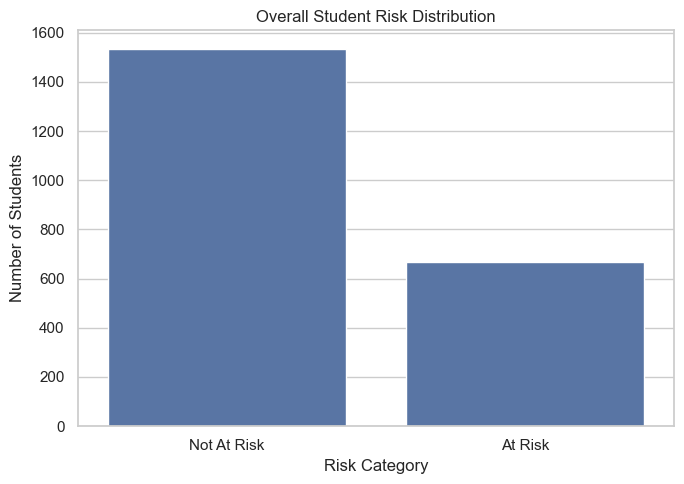

In [50]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="overall_risk"
)

plt.title("Overall Student Risk Distribution")
plt.xlabel("Risk Category")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.savefig("Visualizations/overall_risk_distribution.png")
plt.show()

## Dataset Understanding - Observations

- The dataset contains 2,200 student records and 25 columns.
- Missing values and duplicate records were examined.
- Numerical and categorical variables were identified.
- Student attendance and performance risk categories were analysed.
- Overall student risk distribution was visualized.

### Conclusion

The initial dataset exploration provides an understanding
of student attendance, academic performance, and engagement.
The dataset is now ready for detailed data quality assessment
and preprocessing.